In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

production = pd.read_csv("production.csv")
machines = pd.read_csv("machines.csv")
process = pd.read_csv("process.csv")
materials = pd.read_csv("materials.csv")
inspection = pd.read_csv("inspection.csv")

datasets = {
  "Production": production,
  "Machines": machines,
  "Process": process,
  "Materials": materials,
  "Inspection": inspection
 }

for name, df in datasets.items():
  print("\n", name)
  print("Shape:", df.shape)
  print(df.head())
  print(df.info())


 Production
Shape: (181, 6)
   batch    line    shift  quantity machine material_lot
0  B1001  Line A    Night       776     M07       LOT026
1  B1002  Line B  Morning       775     M01       LOT010
2  B1003  Line B    Night       474     M08       LOT023
3  B1004  Line B  Morning       640     M03       LOT043
4  B1005  Line B  Morning       229     M04       LOT045
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   batch         181 non-null    object
 1   line          181 non-null    object
 2   shift         181 non-null    object
 3   quantity      181 non-null    int64 
 4   machine       181 non-null    object
 5   material_lot  181 non-null    object
dtypes: int64(1), object(5)
memory usage: 8.6+ KB
None

 Machines
Shape: (9, 3)
  machine age_band  operating_hours
0     M01   Medium             7831
1     M02      New            11997
2

In [20]:
for name, df in datasets.items():
      print("\n", name)
      print("Missing values:\n", df.isnull().sum())
      print("Duplicate rows:", df.duplicated().sum())
      print("Data types:\n", df.dtypes)
      print(df.describe(include="all"))


 Production
Missing values:
 batch           0
line            0
shift           0
quantity        0
machine         0
material_lot    0
dtype: int64
Duplicate rows: 1
Data types:
 batch           object
line            object
shift           object
quantity         int64
machine         object
material_lot    object
dtype: object
        batch    line    shift    quantity machine material_lot
count     181     181      181  181.000000     181          181
unique    180       3        3         NaN       9           43
top     B1013  Line B  Morning         NaN     M03       LOT020
freq        2      66       73         NaN      27            8
mean      NaN     NaN      NaN  548.215470     NaN          NaN
std       NaN     NaN      NaN  203.250182     NaN          NaN
min       NaN     NaN      NaN  181.000000     NaN          NaN
25%       NaN     NaN      NaN  382.000000     NaN          NaN
50%       NaN     NaN      NaN  569.000000     NaN          NaN
75%       NaN     NaN     

In [21]:
for col in ["temperature", "pressure", "speed"]:
   if col in process.columns:
      process[col] = process[col].fillna(process[col].median())

In [22]:
print(production[production.duplicated(subset=["batch"], keep=False)])

     batch    line    shift  quantity machine material_lot
12   B1013  Line C  Morning       305     M02       LOT041
180  B1013  Line C  Morning       305     M02       LOT041


In [23]:
production = production.drop_duplicates()

In [24]:
if "defect type" in inspection.columns:
      inspection["defect type"] = (
        inspection["defect type"]
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
   )

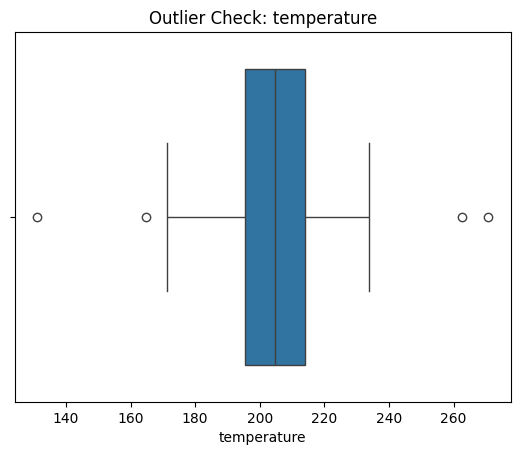

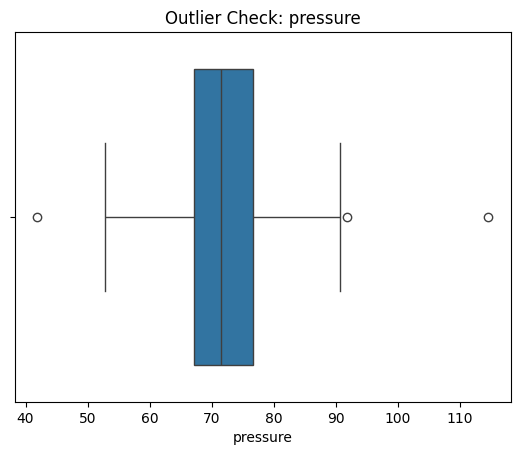

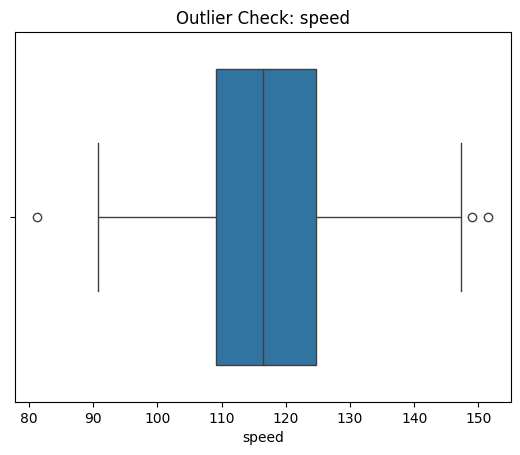

In [25]:
for col in ["temperature", "pressure", "speed"]:
      if col in process.columns:
         sns.boxplot(x=process[col])
         plt.title(f"Outlier Check: {col}")
         plt.show()

In [26]:
for name, df in datasets.items():
      print(name, df.columns.tolist())

Production ['batch', 'line', 'shift', 'quantity', 'machine', 'material_lot']
Machines ['machine', 'age_band', 'operating_hours']
Process ['batch', 'temperature', 'pressure', 'speed']
Materials ['material_lot', 'supplier', 'material_grade']
Inspection ['batch', 'defect_type', 'defect_count', 'quality_status']


In [27]:
combined = production.merge(
      inspection,
          on="batch",
          how="left",
          validate="one_to_many"
  )

print(combined.head())
print(combined.shape)

   batch    line  shift  quantity machine material_lot        defect_type  \
0  B1001  Line A  Night       776     M07       LOT026    Surface Defect    
1  B1001  Line A  Night       776     M07       LOT026  Dimensional Error   
2  B1001  Line A  Night       776     M07       LOT026              Crack   
3  B1001  Line A  Night       776     M07       LOT026           Porosity   
4  B1001  Line A  Night       776     M07       LOT026     Discoloration    

   defect_count quality_status  
0            19           Pass  
1             4           Pass  
2             5           Pass  
3             6           Pass  
4             3           Pass  
(861, 9)


In [28]:
material_check = production.merge(
      materials,
      on="material_lot",
      how="left",
      indicator=True
)

print(material_check["_merge"].value_counts())

_merge
both          173
left_only       7
right_only      0
Name: count, dtype: int64


In [29]:
combined.to_csv("cleaned_manufacturing_data.csv", index=False)

In [30]:
combined["defect_rate"] = (
      combined["defect_count"] /
      combined["quantity"].replace(0, np.nan)
  ) * 100

print(combined[["quantity", "defect_count", "defect_rate"]].head())


   quantity  defect_count  defect_rate
0       776            19     2.448454
1       776             4     0.515464
2       776             5     0.644330
3       776             6     0.773196
4       776             3     0.386598


        total_quantity  total_defects  defect_rate
line                                              
Line B          185792           2398     1.290691
Line C          142049           1430     1.006695
Line A          152705           1397     0.914836


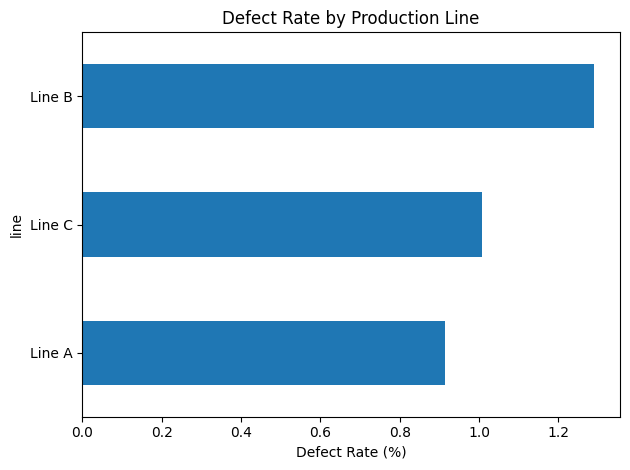

In [31]:
line_analysis = combined.groupby("line").agg(
      total_quantity=("quantity", "sum"),
      total_defects=("defect_count", "sum")
)

line_analysis["defect_rate"] = (
      line_analysis["total_defects"] /
      line_analysis["total_quantity"].replace(0, np.nan)
 ) * 100

print(line_analysis.sort_values("defect_rate", ascending=False))

line_analysis["defect_rate"].sort_values().plot(
    kind="barh", title="Defect Rate by Production Line"
)
plt.xlabel("Defect Rate (%)")
plt.tight_layout()
plt.show()


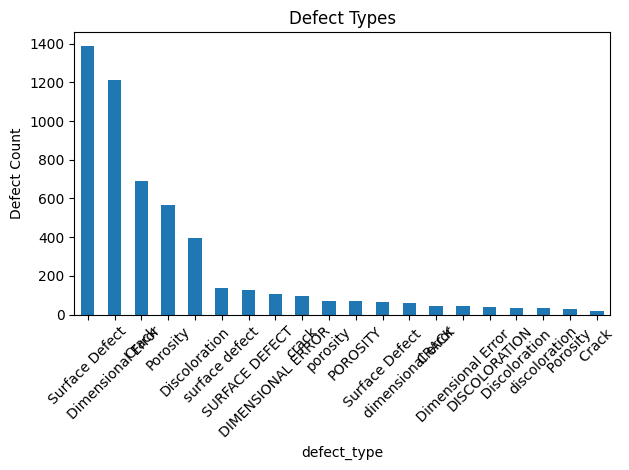

In [32]:
defect_analysis = combined.groupby("defect_type")["defect_count"].sum()
defect_analysis = defect_analysis.sort_values(ascending=False)

defect_analysis.plot(kind="bar", title="Defect Types")
plt.ylabel("Defect Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

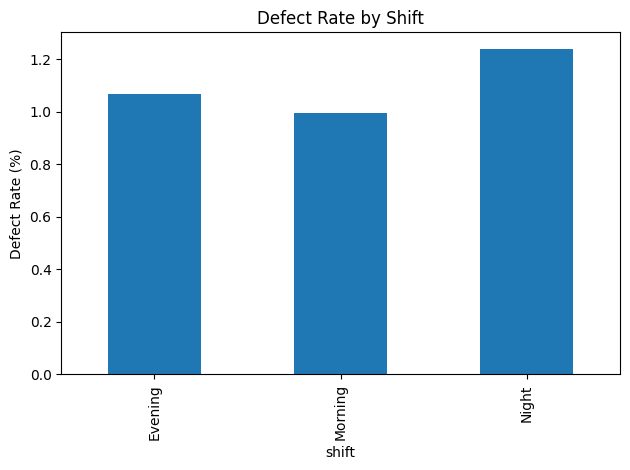

In [33]:
shift_analysis = combined.groupby("shift").agg(
      total_quantity=("quantity", "sum"),
      total_defects=("defect_count", "sum")
)

shift_analysis["defect_rate"] = (
      shift_analysis["total_defects"] /
      shift_analysis["total_quantity"].replace(0, np.nan)
) * 100

shift_analysis["defect_rate"].plot(
    kind="bar", title="Defect Rate by Shift"
)
plt.ylabel("Defect Rate (%)")
plt.tight_layout()
plt.show()


In [34]:
for col in ["temperature", "pressure", "speed"]:
      if col in combined.columns:
         plt.figure(figsize=(6, 4))
         sns.scatterplot(data=combined, x=col, y="defect_rate")
         plt.title(f"{col} vs Defect Rate")
         plt.tight_layout()
         plt.show()

In [38]:
combined_with_materials = combined.merge(materials, on="material_lot", how="left")

supplier_analysis = combined_with_materials.groupby("supplier").agg(
   total_quantity=("quantity", "sum"),
   total_defects=("defect_count", "sum")
)

supplier_analysis["defect_rate"] = (
   supplier_analysis["total_defects"] /
   supplier_analysis["total_quantity"].replace(0, np.nan)
) * 100

print(supplier_analysis.sort_values("defect_rate", ascending=False))

                     total_quantity  total_defects  defect_rate
supplier                                                       
Apex Metals                  119448           1352     1.131873
Pioneer Industrial            87020            966     1.110090
Summit Alloy                 100001           1076     1.075989
Northstar Materials          161167           1671     1.036813


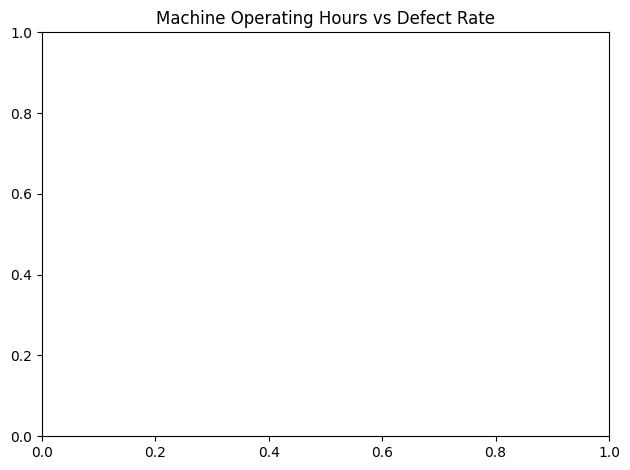

In [39]:
if "operating_hours" in combined.columns:
      sns.scatterplot(
          data=combined,
          x="operating_hours",
          y="defect_rate"
)
plt.title("Machine Operating Hours vs Defect Rate")
plt.tight_layout()
plt.show()

In [42]:
combined_with_machines = combined.merge(machines, on="machine", how="left")

correlation = combined_with_machines["operating_hours"].corr(combined_with_machines["defect_rate"])

print("Correlation:", round(correlation, 3))

if correlation > 0.5:
    print("Strong positive relationship")
elif correlation > 0:
    print("Positive relationship")
elif correlation < -0.5:
    print("Strong negative relationship")
elif correlation < 0:
    print("Negative relationship")
else:
    print("Little or no linear relationship")

Correlation: 0.012
Positive relationship


In [45]:
combined_with_machines["high_operating_hours"] = (
   combined_with_machines["operating_hours"] >
   combined_with_machines["operating_hours"].median()
).astype(int)

combined_with_machines["defect_rate_category"] = pd.cut(
   combined_with_machines["defect_rate"],
   bins=[-float("inf"), 2, 5, float("inf")],
   labels=["Low", "Medium", "High"]
)

print(combined_with_machines[[
    "operating_hours",
    "high_operating_hours",
    "defect_rate",
    "defect_rate_category"
]].head())

   operating_hours  high_operating_hours  defect_rate defect_rate_category
0             8452                     0     2.448454               Medium
1             8452                     0     0.515464                  Low
2             8452                     0     0.644330                  Low
3             8452                     0     0.773196                  Low
4             8452                     0     0.386598                  Low


In [46]:
features = [
      "line",
      "shift",
      "temperature",
      "pressure",
      "speed",
      "operating_hours",
      "supplier",
      "material_grade"
]

features = [col for col in features if col in combined.columns]

print("Selected Features:")
print(features)

Selected Features:
['line', 'shift']


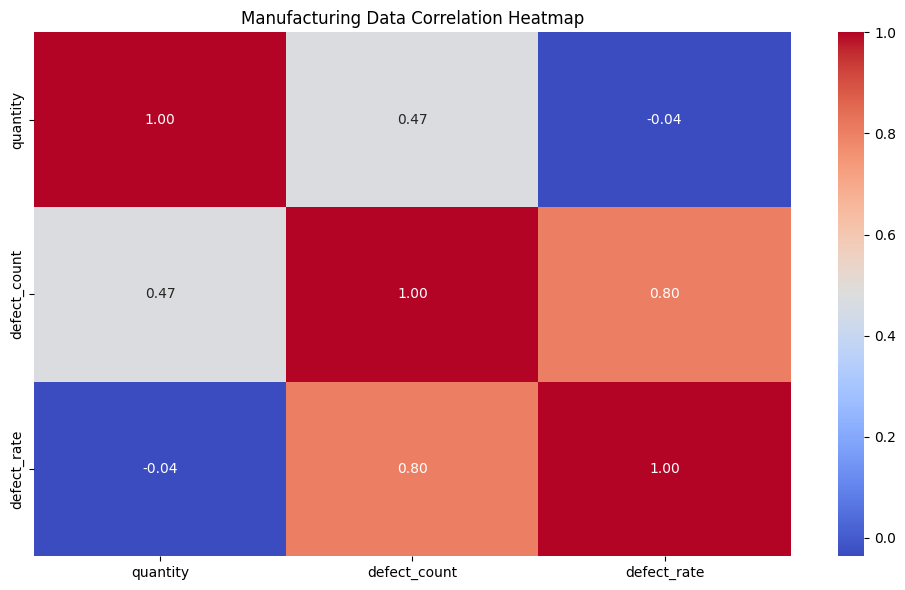

In [47]:
numeric_data = combined.select_dtypes(include="number")

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Manufacturing Data Correlation Heatmap")
plt.tight_layout()
plt.show()

In [48]:
combined.to_csv("cleaned_manufacturing_data.csv", index=False)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


In [53]:

import pandas as pd
from google.colab import files

excel_file_path = 'Manufacturing_Quality_Insight.xlsx'

with pd.ExcelWriter(excel_file_path, engine='openpyxl') as writer:
    combined.to_excel(writer, sheet_name='Cleaned_Data', index=False)
    line_analysis.to_excel(writer, sheet_name='Line_Performance', index=False)
    shift_analysis.to_excel(writer, sheet_name='Shift_Performance', index=False)
    supplier_analysis.to_excel(writer, sheet_name='Supplier_Performance', index=False)
    combined_with_machines.to_excel(writer, sheet_name='Machine_Performance', index=False)

print(f"Success: '{excel_file_path}' created!")

files.download(excel_file_path)


Success: 'Manufacturing_Quality_Insight.xlsx' created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>